# Wind turbine (ODE) — the physics-based recipe

A second running example for the course, alongside the vessel: a **utility-scale wind turbine**
(NREL 5-MW reference). We build it the same way --- **derive $\to$ analyze $\to$ solve $\to$
analyze** --- and meet the quantities every wind engineer works with:

- the **power coefficient** $C_p(\lambda,\beta)$ and tip-speed ratio $\lambda=\omega R/v$,
- the rotor/drivetrain ODE $J\dot\omega = T_{\text{aero}}-T_{\text{gen}}$,
- the **baseline controller**: region-II torque control for maximum power (MPPT) and region-III
  pitch control to hold rated power,
- the resulting **power curve**, and its sensitivity to the uncertain aerodynamics.

The model is defined here (notebook-local) so the later modules --- data-driven, PINN, operator,
CoSTA, discovery --- can reuse the same ground truth.

### Setup — libraries, NREL 5-MW parameters, and the derived operating point

Import NumPy and Matplotlib, apply the course plot style, and define the **NREL 5-MW-like**
constants: air density $\rho=1.225$ kg/m³, rotor radius $R=63$ m (swept area $A=\pi R^2$),
drivetrain inertia $J=3.86\times10^7$ kg·m², rated power $P_\text{rated}=5$ MW, and cut-in/cut-out
wind $v_\text{in}=3$, $v_\text{out}=25$ m/s. The Heier empirical `Cp(lam, beta)` is defined here.
The cell then finds the aerodynamic optimum by scanning $\lambda\in[2,15]$ at zero pitch — yielding
$\lambda_\text{opt}$, $C_p^{\max}$, the region-II torque gain
$K=\tfrac12\rho A R^3 C_p^{\max}/\lambda_\text{opt}^3$, the rated wind
$v_\text{rated}=\big(P_\text{rated}/(\tfrac12\rho A C_p^{\max})\big)^{1/3}$, rated speed
$\omega_\text{rated}=\lambda_\text{opt}v_\text{rated}/R$ and torque
$T_\text{rated}=P_\text{rated}/\omega_\text{rated}$ — and prints them.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))  # -> python/
import numpy as np
import matplotlib.pyplot as plt
from pyutils import set_plot_style; set_plot_style()
np.random.seed(0)

FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)
from pyutils import save_dual, fg

# ---- NREL 5-MW-like parameters ---------------------------------------------
rho = 1.225          # air density [kg/m^3]
R = 63.0             # rotor radius [m]
A = np.pi * R**2     # swept area [m^2]
J = 38.6e6           # drivetrain inertia (low-speed shaft) [kg m^2]
P_rated = 5.0e6      # rated electrical power [W]
v_in, v_out = 3.0, 25.0   # cut-in / cut-out wind speed [m/s]

def Cp(lam, beta):
    "Heier empirical power coefficient; lam = tip-speed ratio, beta = pitch [deg]."
    lam = np.maximum(lam, 1e-6)
    li = 1.0 / (1.0 / (lam + 0.08*beta) - 0.035 / (beta**3 + 1.0))
    return np.maximum(0.5176*(116.0/li - 0.4*beta - 5.0)*np.exp(-21.0/li) + 0.0068*lam, 0.0)

# optimum operating point at zero pitch
_lg = np.linspace(2, 15, 5000); _cp = Cp(_lg, 0.0)
lam_opt = _lg[np.argmax(_cp)]; Cp_max = _cp.max()
v_rated = (P_rated / (0.5*rho*A*Cp_max))**(1/3); omega_rated = lam_opt*v_rated/R
K = 0.5*rho*A*R**3*Cp_max/lam_opt**3        # region-II optimal torque gain
T_rated = P_rated/omega_rated
print(f"lambda_opt={lam_opt:.2f}  Cp_max={Cp_max:.3f}  v_rated={v_rated:.1f} m/s  "
      f"omega_rated={omega_rated:.3f} rad/s ({omega_rated*30/np.pi:.1f} rpm)")

lambda_opt=8.10  Cp_max=0.480  v_rated=11.1 m/s  omega_rated=1.426 rad/s (13.6 rpm)


The printed operating point: $\lambda_\text{opt}=8.10$, $C_p^{\max}=0.480$ (well under the Betz
limit $0.593$), $v_\text{rated}=11.1$ m/s and $\omega_\text{rated}=1.426$ rad/s $=13.6$ rpm. So below
$11.1$ m/s the machine should hold $\lambda=8.1$ to capture $48\%$ of the wind's kinetic energy, and
its rated rotor speed is a leisurely $13.6$ rpm — a $126$ m rotor turns slowly. These constants seed
the controller ($K$, $T_\text{rated}$) and every figure below.

## Step 1 — Derive: rotor dynamics and the power coefficient

The aerodynamic power captured from the wind is
$P_{\text{aero}}=\tfrac12\rho A\,C_p(\lambda,\beta)\,v^3$, with swept area $A=\pi R^2$, tip-speed
ratio $\lambda=\omega R/v$ and blade pitch $\beta$. The dimensionless $C_p$ is the turbine's
aerodynamic signature --- and, like the vessel's hydrodynamic coefficients, it is the *uncertain*
part (measured in wind tunnels / blade-element theory). Newton's law for the drivetrain reads
$$J\,\dot\omega = T_{\text{aero}}-T_{\text{gen}},\qquad
T_{\text{aero}}=\frac{P_{\text{aero}}}{\omega}=\frac{\tfrac12\rho A\,C_p(\lambda,\beta)\,v^3}{\omega}.$$
$C_p$ peaks at a single tip-speed ratio $\lambda_{\text{opt}}$ (Betz-bounded below $0.593$); pitching
the blades reduces it.

**The $C_p$ model.** We use the standard Heier fit
$C_p(\lambda,\beta)=0.5176\,(116/\lambda_i-0.4\beta-5)\,e^{-21/\lambda_i}+0.0068\,\lambda$, with
$1/\lambda_i=1/(\lambda+0.08\beta)-0.035/(\beta^3+1)$, clipped to be non-negative. This cell plots
$C_p$ versus $\lambda$ for pitch $\beta\in\{0,5,10,15\}$ deg (left) and the full
$C_p(\lambda,\beta)$ surface over $\lambda\in[1,14]$, $\beta\in[0,25]$ deg (right), marking the
zero-pitch optimum.

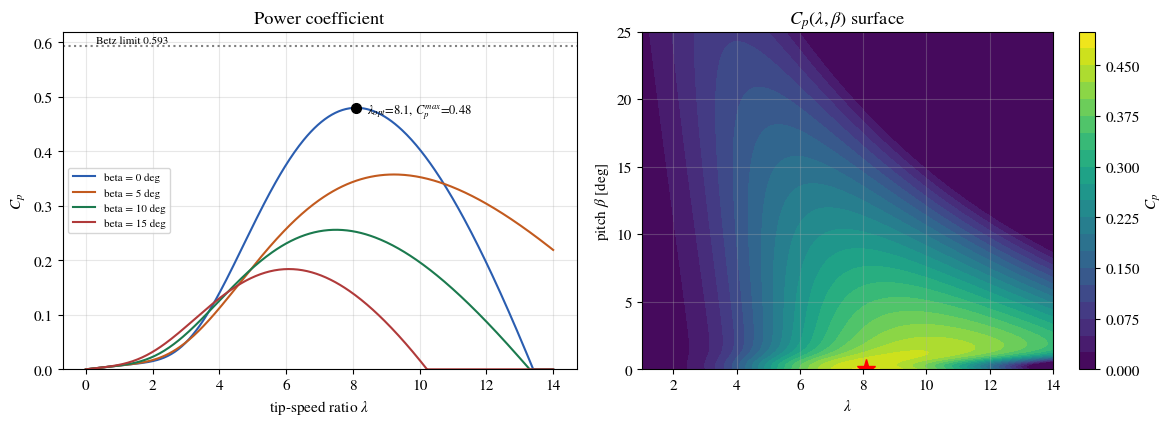

In [2]:
lam = np.linspace(0, 14, 400)

def plot_wind_cp():
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
    for b in [0, 5, 10, 15]:
        ax[0].plot(lam, Cp(lam, b), label=f'beta = {b} deg')
    ax[0].plot(lam_opt, Cp_max, 'o', color=fg(), ms=7)
    ax[0].annotate(f'$\\lambda_{{opt}}$={lam_opt:.1f}, $C_p^{{max}}$={Cp_max:.2f}',
                   (lam_opt, Cp_max), textcoords='offset points', xytext=(8, -4), fontsize=9)
    ax[0].axhline(16/27, ls=':', c='gray'); ax[0].text(0.3, 16/27+0.005, 'Betz limit 0.593', fontsize=8)
    ax[0].set(xlabel='tip-speed ratio $\\lambda$', ylabel='$C_p$', title='Power coefficient',
              ylim=(0, 0.62)); ax[0].legend(fontsize=8)
    LL, BB = np.meshgrid(np.linspace(1, 14, 200), np.linspace(0, 25, 200))
    cf = ax[1].contourf(LL, BB, Cp(LL, BB), levels=20, cmap='viridis')
    ax[1].plot(lam_opt, 0, 'r*', ms=14); plt.colorbar(cf, ax=ax[1], label='$C_p$')
    ax[1].set(xlabel='$\\lambda$', ylabel='pitch $\\beta$ [deg]', title='$C_p(\\lambda,\\beta)$ surface')
    plt.tight_layout()

save_dual(plot_wind_cp, 'wind_cp', FIG)
plt.show()

**Left:** at zero pitch $C_p$ rises to its peak $C_p^{\max}\approx0.48$ at
$\lambda_\text{opt}\approx8.1$ (black dot), comfortably under the dotted Betz limit $0.593$;
increasing pitch both **lowers and shifts** the peak — $\beta=5$ deg tops out near $0.36$, and
$\beta=15$ deg barely reaches $0.19$ before collapsing to zero past $\lambda\approx10$. **Right:** the
$C_p(\lambda,\beta)$ surface makes the single bright optimum obvious — the red star at
$(\lambda_\text{opt},0)$ — with $C_p$ falling off in every direction. Region-II control is literally
the job of staying on that ridge; region-III control is deliberately climbing *up* in $\beta$ to shed
power.

## Step 2 & 3 — The baseline controller and the closed loop

Two regimes, the textbook variable-speed variable-pitch strategy:

- **Region II** (below rated wind): keep $\beta=0$ and set generator torque $T_{\text{gen}}=K\omega^2$
  with $K=\tfrac12\rho A R^3 C_p^{\max}/\lambda_{\text{opt}}^3$ (equivalently
  $\tfrac12\rho\pi R^5 C_p^{\max}/\lambda_{\text{opt}}^3$, since $A=\pi R^2$). The steady state of
  $J\dot\omega=T_\text{aero}-K\omega^2$ sits exactly at $\lambda_{\text{opt}}$, so the law
  **tracks the optimum automatically**, extracting the maximum power (MPPT).
- **Region III** (above rated): the torque saturates at $T_{\text{rated}}$ and a **pitch PI
  controller** ($K_p=18$, $K_i=6$, with anti-windup, pitch clamped to $[0,40]$ deg) feathers the
  blades on the error $\omega-\omega_\text{rated}$ to hold rated speed and shed the excess power.

We integrate $J\dot\omega=T_{\text{aero}}-T_{\text{gen}}$ (semi-implicit Euler, $\Delta t=0.05$ s)
under a prescribed wind, and trace the **power curve** by driving $45$ constant winds across
$[v_\text{in},v_\text{out}]=[3,25]$ m/s to steady state.

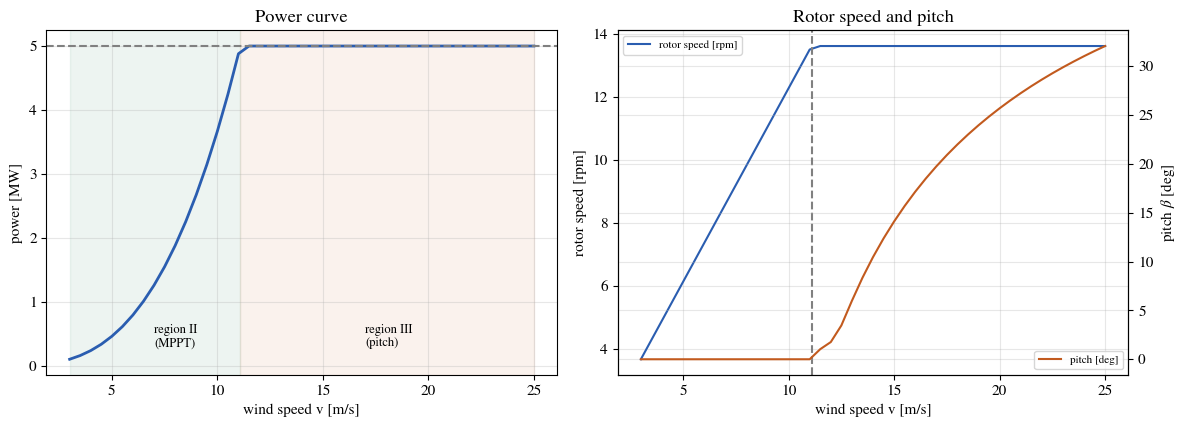

In [3]:
Kp, Ki = 18.0, 6.0      # pitch PI gains
def simulate(v_fn, t_end=300.0, dt=0.05, omega0=None):
    n = int(t_end/dt); t = np.linspace(0, n*dt, n+1)
    omega = omega0 if omega0 is not None else min(lam_opt*float(v_fn(0.0))/R, omega_rated)
    beta = 0.0; integ = 0.0
    OM, BE, P, CP = [omega], [beta], [], []
    for k in range(n):
        v = float(v_fn(t[k])); cp = Cp(omega*R/v, beta)
        T_aero = 0.5*rho*A*cp*v**3 / max(omega, 0.1)
        T_gen = min(K*omega**2, T_rated)
        err = omega - omega_rated; integ += err*dt
        beta_cmd = Kp*err + Ki*integ; beta = min(max(beta_cmd, 0.0), 40.0)
        if beta != beta_cmd: integ = (beta - Kp*err)/Ki          # anti-windup
        omega = max(omega + dt*(T_aero - T_gen)/J, 0.1)
        OM.append(omega); BE.append(beta); P.append(T_gen*omega); CP.append(cp)
    return t, np.array(OM), np.array(BE), np.array(P), np.array(CP)

# steady operating point per wind speed -> the power curve
vv = np.linspace(v_in, v_out, 45); Pq, Wq, Bq = [], [], []
for v0 in vv:
    _, OM, BE, P, _ = simulate(lambda s: v0, t_end=150)
    Pq.append(P[-1]); Wq.append(OM[-1]); Bq.append(BE[-1])
Pq, Wq, Bq = np.array(Pq), np.array(Wq), np.array(Bq)

def plot_wind_power_curve():
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
    ax[0].plot(vv, Pq/1e6, 'C0', lw=2); ax[0].axhline(P_rated/1e6, ls='--', c='gray')
    ax[0].axvspan(v_in, v_rated, color='C2', alpha=0.08); ax[0].axvspan(v_rated, v_out, color='C1', alpha=0.08)
    ax[0].text(7, 0.3, 'region II\n(MPPT)', fontsize=9); ax[0].text(17, 0.3, 'region III\n(pitch)', fontsize=9)
    ax[0].set(xlabel='wind speed v [m/s]', ylabel='power [MW]', title='Power curve')
    ax[1].plot(vv, Wq*30/np.pi, 'C0', label='rotor speed [rpm]')
    ax2 = ax[1].twinx(); ax2.plot(vv, Bq, 'C1', label='pitch [deg]')
    ax[1].axvline(v_rated, ls='--', c='gray')
    ax[1].set(xlabel='wind speed v [m/s]', ylabel='rotor speed [rpm]', title='Rotor speed and pitch')
    ax2.set_ylabel('pitch $\\beta$ [deg]')
    ax[1].legend(loc='upper left', fontsize=8); ax2.legend(loc='lower right', fontsize=8)
    plt.tight_layout()

save_dual(plot_wind_power_curve, 'wind_power_curve', FIG)
plt.show()

**Left (power curve):** power climbs like $v^3$ through **region II** (green band, MPPT) — from
$\approx0.1$ MW at cut-in to $5$ MW at $v_\text{rated}\approx11$ m/s — then holds flat at the rated
$5$ MW through **region III** (orange band) all the way to cut-out. **Right:** rotor speed ramps
linearly from $\approx3.7$ to $13.6$ rpm as it tracks $\lambda_\text{opt}$, then saturates at
$13.6$ rpm; the pitch $\beta$ stays at $0$ below rated and rises smoothly to $\approx32$ deg by
$25$ m/s — the two actuators handing off exactly at the dashed rated line. This cubic-then-flat curve
is the most recognizable object in wind engineering.

## Step 4 — Analyze: closed-loop response to turbulent wind

Real wind is turbulent. We drive the closed loop for $300$ s with a **mean wind of $12$ m/s**
(deliberately just above $v_\text{rated}=11.1$, so the machine straddles the region II/III boundary)
plus a realistic gust process: an Ornstein–Uhlenbeck (low-pass-filtered) fluctuation with turbulence
intensity $\text{TI}=12\%$ and correlation time $\tau=20$ s. The controller switches seamlessly: in
lulls it runs region-II MPPT (pitch idle); in gusts the rotor tries to over-speed and the pitch
feathers to cap power near $5$ MW. The cell prints the mean and peak power over the run.

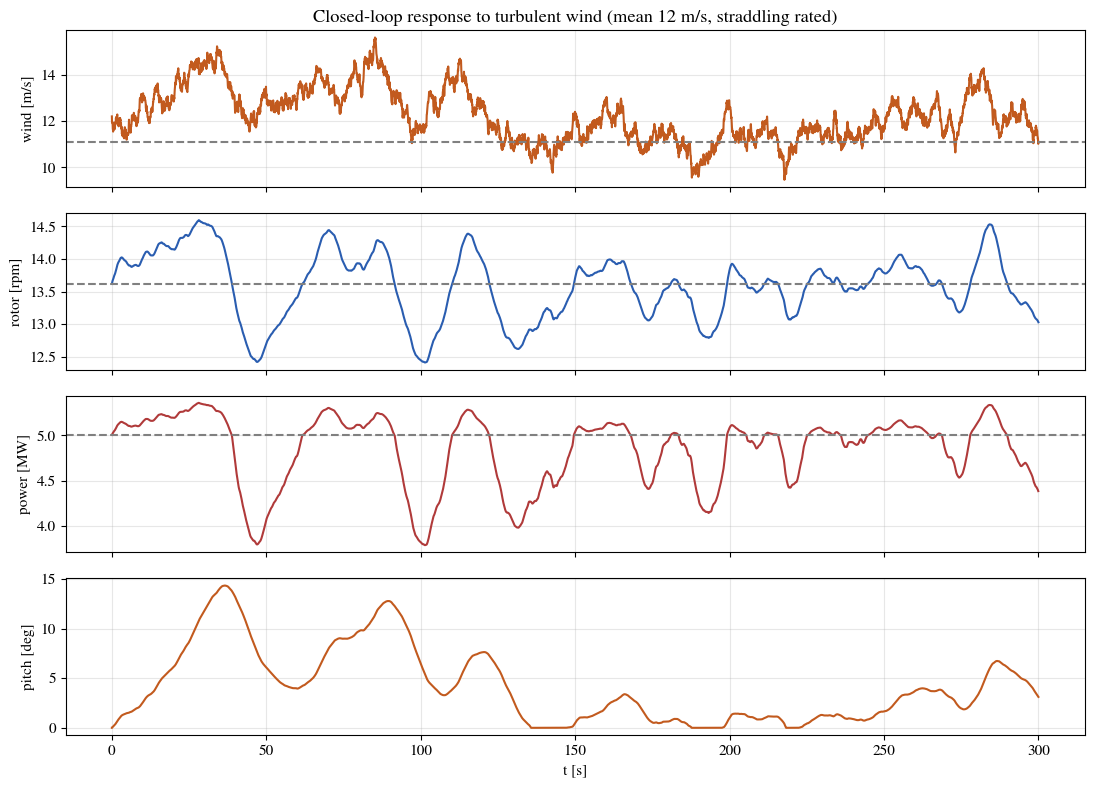

power: mean 4.84 MW, max 5.36 MW; pitch active above rated only


In [4]:
def turbulent_wind(v_mean, t_end=300.0, dt=0.05, TI=0.12, tau=20.0, seed=1):
    rng = np.random.default_rng(seed); n = int(t_end/dt); u = 0.0; out = []
    sig = TI*v_mean
    for _ in range(n+1):
        u += dt*(-u/tau) + sig*np.sqrt(2*dt/tau)*rng.standard_normal(); out.append(v_mean + u)
    tt = np.linspace(0, n*dt, n+1); return lambda s: np.interp(s, tt, out), tt, np.array(out)

vfn, tt, vs = turbulent_wind(12.0, seed=3)
t, OM, BE, P, CP = simulate(vfn, t_end=300)

def plot_wind_response():
    fig, ax = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
    ax[0].plot(tt, vs, 'C7'); ax[0].axhline(v_rated, ls='--', c='gray'); ax[0].set(ylabel='wind [m/s]')
    ax[1].plot(t, OM*30/np.pi, 'C0'); ax[1].axhline(omega_rated*30/np.pi, ls='--', c='gray'); ax[1].set(ylabel='rotor [rpm]')
    ax[2].plot(t[:-1], P/1e6, 'C3'); ax[2].axhline(P_rated/1e6, ls='--', c='gray'); ax[2].set(ylabel='power [MW]')
    ax[3].plot(t, BE, 'C1'); ax[3].set(ylabel='pitch [deg]', xlabel='t [s]')
    ax[0].set_title('Closed-loop response to turbulent wind (mean 12 m/s, straddling rated)')
    plt.tight_layout()

save_dual(plot_wind_response, 'wind_response', FIG)
plt.show()
print(f'power: mean {P.mean()/1e6:.2f} MW, max {P.max()/1e6:.2f} MW; pitch active above rated only')

The four stacked panels show the regime-switching directly. **Wind** wanders between $\approx9.5$ and
$15.5$ m/s about the dashed rated line; **rotor speed** tracks it, dipping to $\approx12.4$ rpm in
lulls and rising to $\approx14.6$ rpm in gusts around the $13.6$ rpm setpoint; **power** is held near
the $5$ MW cap in gusts but sags to $\approx3.8$–$4$ MW whenever the wind drops below rated;
**pitch** is exactly zero during those lulls (region II) and spikes to $\approx14$ deg during the
strongest gusts (region III). The printed summary — **mean $4.84$ MW, max $5.36$ MW** — quantifies
it: the machine spends much of the time capped, but the sub-rated lulls pull the average below $5$
MW. This regime-switching dynamic is exactly what the next module's data-driven surrogate must
reproduce.

## Aspect: sensitivity to the uncertain aerodynamics

The power curve is only as good as $C_p$. Blade erosion, fouling, icing or simply an imperfect
aerodynamic model scale the achievable $C_p$ --- and, since $P_\text{aero}\propto C_p$, the captured
power scales with it directly in region II. We sweep a multiplier $C_p\to s\,C_p$ for
$s\in\{0.90,1.0,1.10\}$ ("eroded", "nominal", "ideal") and also integrate each curve against a crude
Gaussian wind distribution (centred at $9$ m/s) to get a representative mean-power scalar. This is
the "amber" quantity that the data-driven, hybrid and discovery modules identify, correct, or
rediscover.

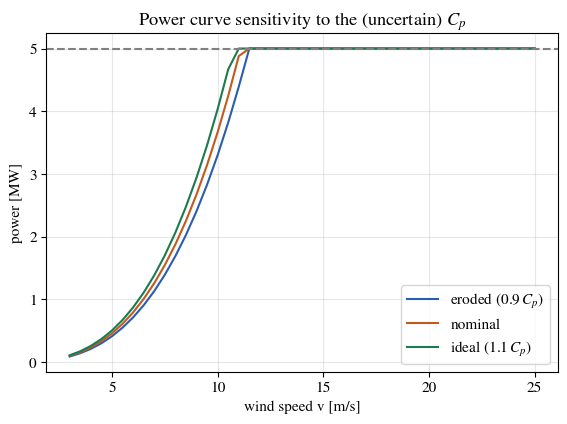

mean power [MW] under a representative wind dist: {0.9: np.float64(2.68), 1.0: np.float64(2.86), 1.1: np.float64(3.02)}


In [5]:
def power_curve(cp_scale):
    Cp_s = lambda l, b: cp_scale*Cp(l, b)
    Pc = []
    for v0 in vv:
        # quick steady region-II/III estimate with scaled Cp
        Pav = 0.5*rho*A*cp_scale*Cp_max*v0**3
        Pc.append(min(Pav, P_rated))
    return np.array(Pc)

def plot_wind_sensitivity():
    fig, ax = plt.subplots(figsize=(6.6, 4.4))
    for s, lab in zip([0.90, 1.0, 1.10], ['eroded ($0.9\\,C_p$)', 'nominal', 'ideal ($1.1\\,C_p$)']):
        ax.plot(vv, power_curve(s)/1e6, label=lab)
    ax.axhline(P_rated/1e6, ls='--', c='gray')
    ax.set(xlabel='wind speed v [m/s]', ylabel='power [MW]',
           title='Power curve sensitivity to the (uncertain) $C_p$'); ax.legend()

save_dual(plot_wind_sensitivity, 'wind_sensitivity', FIG)
plt.show()
# annual-energy-style scalar: integrate power over a representative wind distribution
from numpy import trapezoid as trapz  # numpy>=2 name
pdf = np.exp(-((vv-9)/4)**2)  # crude wind distribution
aep = {s: trapz(power_curve(s)*pdf, vv)/trapz(pdf, vv)/1e6 for s in [0.9, 1.0, 1.1]}
print('mean power [MW] under a representative wind dist:', {k: round(v, 2) for k, v in aep.items()})

**Below rated the three curves fan out** in proportion to the $C_p$ multiplier — the "ideal"
$1.1\,C_p$ curve (green) reaches rated power at a *lower* wind, while the "eroded" $0.9\,C_p$ curve
(blue) needs more wind for the same output — and above $\approx12$ m/s they all collapse onto the
same $5$ MW cap, because region III sheds whatever is extra regardless of $C_p$. The mean-power
scalar makes the cost concrete: $\{0.9,1.0,1.1\}\,C_p$ give $\{2.68,\,2.86,\,3.02\}$ MW under the
representative wind distribution — a $\pm10\%$ change in $C_p$ moving mean energy by roughly
$\pm6\%$, i.e. real money over a turbine's life. Localizing the model's weakness to this one function
is what makes the hybrid methods of the rest of the course worth doing.

**Hand-off.** A first-principles turbine model gives the power curve, the control regions and
the dynamic response --- but it hinges on $C_p(\lambda,\beta)$ and the drivetrain parameters, which
drift with blade condition and are never known exactly. That gap drives the rest of the course:
learn the power curve from SCADA data (Chapter~\ref{ch:ddm}), identify the parameters with a PINN
(Chapter~\ref{ch:pinn}), learn the wind-to-power operator (Chapter~\ref{ch:deeponet}), correct an
unmodeled degradation with CoSTA (Chapter~\ref{ch:costa}), and rediscover the laws
(Chapter~\ref{ch:eqdiscovery}). The turbine's **wake** --- how it slows the wind for turbines
behind it --- is the spatial companion problem, taken up with the Fourier neural operator
(Chapter~\ref{ch:fno}).